In [1]:
import re
import os
import pandas as pd
import numpy as np
from Bio import SeqIO
from datetime import datetime
from plotnine import *
import geopandas as gpd
import geodatasets
from shapely.geometry import Polygon, MultiPolygon

In [2]:
# Goal: combine detections into a list of dates and counts

In [3]:
# Upload US Detections

RECENT_US = "./metadata/detections_data/HPAI Detections in Wild Birds (dwnld 2025-01-31).csv"

us_detect = pd.read_csv(RECENT_US, sep = ',')

In [4]:
# Upload Canadian Detections

RECENT_CAN = "./metadata/detections_data/HPAI_IAHP_Wildlife_Faune__file_fichie.csv"

can_detect = pd.read_csv(RECENT_CAN, sep = ',')

In [5]:
# I want a big dataframe with all detections and the following columns
# Date
# Country
# State/Province
# Flyway
# Latitude group
# Host
# Host Order

In [6]:
# Fix date columns

print(us_detect.columns)
print(can_detect.columns)

print(type(us_detect["Collection Date"]))
print(type(can_detect["Collection Date"]))

Index(['State', 'County', 'Collection Date', 'Date Detected', 'HPAI Strain',
       'Bird Species', 'WOAH Classification', 'Sampling Method',
       'Submitting Agency'],
      dtype='object')
Index(['Province', 'Common Name', 'Scientific Name', 'Animal Class',
       'Bird Group', 'Collection Date', 'Status', 'Result', 'Strain',
       'Lineage', 'Result Authorised Date', 'CCSNAME'],
      dtype='object')
<class 'pandas.core.series.Series'>
<class 'pandas.core.series.Series'>


In [7]:
# Filter to dates needed

years_to_include = [2021, 2022, 2023, 2024]

us_detect["Collection Date"] = pd.to_datetime(us_detect["Collection Date"], errors='coerce')
us_detect_timeframe = us_detect[us_detect["Collection Date"].dt.year.isin(years_to_include)]

can_detect["Collection Date"] = pd.to_datetime(can_detect["Collection Date"], errors='coerce')
can_detect_timeframe = can_detect[can_detect["Collection Date"].dt.year.isin(years_to_include)]

In [8]:
print(len(us_detect_timeframe))
print(len(can_detect_timeframe))

10810
2694


In [9]:
# The US detections are only wild birds, but the Canadian detections are all wildlife
# Want to filter Canadian detections to just wild birds

can_detect_timeframe_avian = can_detect_timeframe[can_detect_timeframe["Animal Class"] == "Avian"]
print(len(can_detect_timeframe_avian))

2525


In [10]:
# Add Country columns

us_detect_timeframe.loc[0:, "Country"] = "United_States"
can_detect_timeframe_avian.loc[0:, "Country"] = "Canada"

/var/folders/8z/j5vh6t990rj40lqqxtsr69z00000gp/T/ipykernel_4587/2401610591.py:3: SettingWithCopyWarning: 
A value is trying to be set on a copy of a slice from a DataFrame.
Try using .loc[row_indexer,col_indexer] = value instead

See the caveats in the documentation: https://pandas.pydata.org/pandas-docs/stable/user_guide/indexing.html#returning-a-view-versus-a-copy
/var/folders/8z/j5vh6t990rj40lqqxtsr69z00000gp/T/ipykernel_4587/2401610591.py:4: SettingWithCopyWarning: 
A value is trying to be set on a copy of a slice from a DataFrame.
Try using .loc[row_indexer,col_indexer] = value instead

See the caveats in the documentation: https://pandas.pydata.org/pandas-docs/stable/user_guide/indexing.html#returning-a-view-versus-a-copy


In [11]:
# Concatenate

all_detect = pd.concat([us_detect_timeframe, can_detect_timeframe_avian], axis = 0, join = "outer", ignore_index = True)

In [12]:
# Add a column for state or province

# Make sure there are no rows with a value in both State and Provice
both_filled = all_detect[all_detect["State"].notna() & all_detect["Province"].notna()]
print(both_filled)

# State for detections from the US
# Province for detections from Canada

all_detect["Location"] = all_detect["State"].fillna(all_detect["Province"])

Empty DataFrame
Columns: [State, County, Collection Date, Date Detected, HPAI Strain, Bird Species, WOAH Classification, Sampling Method, Submitting Agency, Country, Province, Common Name, Scientific Name, Animal Class, Bird Group, Status, Result, Strain, Lineage, Result Authorised Date, CCSNAME]
Index: []

[0 rows x 21 columns]


In [13]:
# Check on the Collection Date column

print(all_detect["Collection Date"].value_counts())

Collection Date
2023-11-18    142
2022-10-15    126
2022-09-10    110
2023-10-14    106
2022-11-05    104
             ... 
2024-04-28      1
2024-04-11      1
2024-04-19      1
2024-03-17      1
2024-08-09      1
Name: count, Length: 884, dtype: int64


In [14]:
# Stardardize the state names in all_detect
all_detect["Location"] = all_detect["Location"].str.lower()
all_detect["Location"] = all_detect["Location"].str.replace(" ", "").replace("-", "").replace(".", "")

# Also gotta change newfoundlandandlabrador 

# all_detect.loc[all_detect["Location"].isin(["newfoundlandandlabrador"])
all_detect["Location"] = all_detect["Location"].str.replace("newfoundlandandlabrador", "newfoundland")                           

In [15]:
# Map to flyway and latitude group

locations_csv = "./metadata/helpful_lists/flywayregions_biggerlist.csv"

locations = pd.read_csv(locations_csv, sep = ',') 

locations_dict = locations.set_index("location").to_dict(orient="index") # Turn this CSV into a dictionary

# Make individual dictionaries for flyway and latitude group
flyways_dict = {loc: data['flyway'] for loc, data in locations_dict.items()}
latitude_dict = {loc: data['latitude_group'] for loc, data in locations_dict.items()}

# Map to the detections
all_detect["Flyway"] = all_detect["Location"].map(flyways_dict)
all_detect["Latitude_Group"] = all_detect["Location"].map(latitude_dict)

In [16]:
# Add a column for host

# Bird Species for detections from the US
# Common Name for detections from Canada

all_detect["Avian_Host"] = all_detect["Bird Species"].fillna(all_detect["Common Name"])

In [17]:
# Standardize the host names
all_detect["Avian_Host"] = all_detect["Avian_Host"].str.lower()
all_detect["Avian_Host"] = all_detect["Avian_Host"].str.replace(" ", "")
all_detect["Avian_Host"] = all_detect["Avian_Host"].str.replace("-", "")
all_detect["Avian_Host"] = all_detect["Avian_Host"].str.replace(".", "")
all_detect["Avian_Host"] = all_detect["Avian_Host"].str.replace("'", "")
all_detect["Avian_Host"] = all_detect["Avian_Host"].str.replace("_","")

In [18]:
# Function: drop the hybrid, remove (unidentified), and replace "northenpintail" with "northernpintail"

def alter_us_detections_hosts(df):
    # Loop through DataFrame rows
    df["Avian_Host"] = df["Avian_Host"].str.lower()
    df["Avian_Host"] = df["Avian_Host"].astype(str).str.replace(" ", "", regex = False).str.replace("-", "", regex = False).str.replace(".", "", regex = False).str.replace("'", "").str.replace("_","", regex = False)
    others = ["(anatidae)", "(duck)", "(gullsandterns)", "(anatidae)"]
    
    for index, row in df.iterrows():
        host_name = str(row["Avian_Host"])

        # First, remove the mallard/blackduckhybrid cause it's weird
        if host_name == "mallard/blackduckhybrid":
            df.drop(index, axis=0, inplace=True)  # Drop row in-place

        # Fix the typo in "northenpintail"
        elif host_name == "northenpintail":  # Correct typo check
            host_name = host_name.replace("northenpintail", "northernpintail")
            df.at[index, "Avian_Host"] = host_name  # Update the DataFrame

        # Remove "(unidentified)" from species names
        elif "(unidentified)" in host_name:  # Check if "(unidentified)" is in the name
            host_name = host_name.replace("(unidentified)", "")
            df.at[index, "Avian_Host"] = host_name  # Update the DataFrame

        # Remove other things from species names
        elif any(n in host_name for n in others):  # Check if something else is in the name
            for n in others:
                host_name = host_name.replace(n, "")
            df.at[index, "Avian_Host"] = host_name  # Update the DataFrame

        else:
            pass
    
    return df

In [19]:
all_detect = alter_us_detections_hosts(all_detect)

In [20]:
# Map to host order

birdies = pd.read_csv("./metadata/helpful_lists/NAm_host_list_order-domesticstat.csv", sep = ",", encoding='latin-1')

birdies_dict = birdies.set_index("strain_host").to_dict(orient="index")

all_detect["Host_Order"] = all_detect["Avian_Host"].map(lambda host: birdies_dict.get(host, {}).get("order"))
all_detect["Corrected_Avian_Host"] = all_detect["Avian_Host"].map(lambda host: birdies_dict.get(host, {}).get("corrected_host"))
all_detect["Host_Broad"] = all_detect["Avian_Host"].map(lambda host: birdies_dict.get(host, {}).get("host_group2"))

all_detect["Host_Order"] = all_detect["Host_Order"].fillna("Unknown")

In [21]:
print(len(all_detect))
print(all_detect["Country"].value_counts())

#print(all_detect["Flyway"].value_counts())
#print(all_detect["Latitude_Group"].value_counts())
#print(all_detect["Host_Order"].value_counts())

13331
Country
United_States    10806
Canada            2525
Name: count, dtype: int64


In [22]:
# Add a column to indicate how each bird was sampled

all_detect["test_combine_status"] = all_detect["Sampling Method"].combine_first(all_detect["Status"])
print(all_detect["test_combine_status"].value_counts())

sampling_method_dict = {"Morbidity/Mortality":"Dead",
                       "Hunter harvest":"Agency/Hunter_Harvest",
                       "Dead":"Dead",
                       "Live bird":"Live",
                       "Agency harvest":"Agency/Hunter_Harvest",
                       "Hunter Harvest":"Agency/Hunter_Harvest",
                       "Live":"Live",
                       "Harvest":"Agency/Hunter_Harvest",
                       "Euthanized":"Euthanized"
                       }

all_detect["Sample_Method"] = all_detect["test_combine_status"].map(sampling_method_dict)

test_combine_status
Morbidity/Mortality    5688
Hunter harvest         3505
Dead                   1737
Live bird              1149
Agency harvest          283
Hunter Harvest          181
Live                    178
Harvest                  69
Euthanized               55
Name: count, dtype: int64


In [75]:
# Print

columns_keep = ["Collection Date", "Location", "Avian_Host", "Country", "Flyway", "Latitude_Group", "Host_Order", "Host_Broad", "Sample_Method", "Corrected_Avian_Host"]

all_detect_final = all_detect.loc[0:, columns_keep]
print(all_detect_final["Country"].value_counts())

all_detect_final.to_csv("./metadata/detections_data/combinedNAm_detections_2021-2024.csv", sep = ',')

Country
United_States    10806
Canada            2525
Name: count, dtype: int64


In [76]:
# If necessary (if you just want to edit the counts dataset without messing with the other one), start here

all_detect_final = pd.read_csv("./metadata/detections_data/combinedNAm_detections_2021-2024.csv", sep = ',')

In [4]:
print(all_detect_final.columns)

Index(['Unnamed: 0', 'Collection Date', 'Location', 'Avian_Host', 'Country',
       'Flyway', 'Latitude_Group', 'Host_Order', 'Host_Broad',
       'Sample_Method'],
      dtype='object')


In [17]:
all_detect_ans = all_detect_final[all_detect_final["Host_Order"] == "anseriformes"]
print(len(all_detect_ans))

print(all_detect_ans["Avian_Host"].value_counts())

8231
Avian_Host
mallard                     1799
canadagoose                 1254
snowgoose                    916
greenwingedteal              907
bluewingedteal               621
americanwigeon               472
gadwall                      340
woodduck                     333
northernpintail              233
northernshoveler             219
cacklinggoose                148
rosssgoose                   145
americanblackduck            104
ringneckedduck               103
commoneider                   81
trumpeterswan                 68
lesserscaup                   67
muscovyduck                   42
redheadduck                   39
hoodedmerganser               38
muteswan                      33
tundraswan                    31
cinnamonteal                  29
greaterwhitefrontedgoose      29
commongoldeneye               24
whitewingedscoter             23
bufflehead                    17
canvasback                    14
blackscoter                   11
ruddyduck                  

In [69]:
# Make a list of detections per location per month

all_detect_final["year_month"] = all_detect_final["Collection Date"].str.split("-", expand = True)[0] + "_" + all_detect_final["Collection Date"].str.split("-", expand = True)[1]

all_detect_final["year_month_loc"] = all_detect_final["year_month"] + "_" + all_detect_final["Location"]

all_detect_locationovertime = pd.DataFrame(all_detect_final["year_month_loc"].value_counts())

total_detect = all_detect_locationovertime["count"].sum()
print(total_detect)
all_detect_locationovertime["percent"] = 100 * (all_detect_locationovertime["count"] / total_detect)
print(all_detect_locationovertime["percent"].sum())

# all_detect_locationovertime.to_csv("./metadata/detections_data/detections_per_location.csv", sep = ",")

13335
99.99999999999999


In [74]:
# Some calculations (don't mind this stuff at all)

all_detect_locationovertime_reindex = all_detect_locationovertime.reset_index()
all_detect_locationovertime_reindex["year_month"] = all_detect_locationovertime_reindex["year_month_loc"].str.split("_", expand = True)[0] + "_" + all_detect_locationovertime_reindex["year_month_loc"].str.split("_", expand = True)[1]

fall_2023_limiting = all_detect_locationovertime_reindex.loc[all_detect_locationovertime_reindex["year_month"].isin(["2023_09", "2023_10", "2023_11", "2023_12"])]
print(fall_2023_limiting["percent"].sum())

18.98012748406449


In [40]:
# I then want a smaller dataframe with just dates and counts

all_detect_counts = pd.DataFrame(all_detect_final["Collection Date"].value_counts()).rename({"Collection Date":"dates", "count":"incidence"}, axis = 1)

In [41]:
# Sort according to increasing date

all_detect_counts.index = pd.to_datetime(all_detect_counts.index)
all_detect_counts = all_detect_counts.sort_index()

In [42]:
all_detect_counts.head()

,incidence
Collection Date,
2021-11-04,1
2021-11-26,1
2021-12-12,1
2021-12-24,2
2021-12-29,1


In [43]:
# Print

all_detect_counts.to_csv("./metadata/detections_data/combinedNAm_detections_2021-2024_COUNTS.csv", sep = ',')

In [44]:
# EpiEstim requires data from each day of an outbreak, I think

In [45]:
# 2. Create a complete date range from the first to the last date
full_index = pd.date_range(start=all_detect_counts.index.min(), end=all_detect_counts.index.max(), freq='D')

# 3. Reindex the DataFrame to the full date range and fill missing counts with 0
all_detect_counts_fulldates = all_detect_counts.reindex(full_index, fill_value=0)

# 4. (Optional) Rename the index and reset if needed
all_detect_counts_fulldates.index.name = 'dates'

all_detect_counts_fulldates.head()

,incidence
dates,
2021-11-04,1
2021-11-05,0
2021-11-06,0
2021-11-07,0
2021-11-08,0


In [46]:
all_detect_counts_fulldates.to_csv("./metadata/detections_data/combinedNAm_detections_2021-2024_COUNTS_fulldates.csv", sep = ',')

In [27]:
# Counts for certain hosts only

anseriformes = ["anseriformes"]
shorebirds = ["charadriiformes", "suliformes", "pelecaniformes", "procellariiformes"] 
# what to do with grebes (podicipediformes) and loons (gaviiformes)?
# When making my host order DTA, I left grebes and loons in "other", not in shorebirds or duckies
raptors_owls = ["accipitriformes", "falconiformes", "strigiformes"]

# Subset all_detects_final down to correct order
# host_detect = all_detect_final[all_detect_final["Host_Order"].isin(anseriformes)]
# host_detect = all_detect_final[all_detect_final["Host_Order"].isin(shorebirds)]
host_detect = all_detect_final[all_detect_final["Host_Order"].isin(raptors_owls)]
print(len(host_detect))

# Make a dataframe of counts
host_detect_counts = pd.DataFrame(host_detect["Collection Date"].value_counts()).rename({"Collection Date":"dates", "count":"incidence"}, axis = 1)
host_detect_counts.index = pd.to_datetime(host_detect_counts.index)
host_detect_counts = host_detect_counts.sort_index()

# Fill in the dates
full_index_hosts = pd.date_range(start=host_detect_counts.index.min(), end=host_detect_counts.index.max(), freq='D')
host_detect_counts_fulldates = host_detect_counts.reindex(full_index_hosts, fill_value=0)

2909


In [28]:
# Print the above
# host_detect_counts_fulldates.to_csv("./metadata/detections_data/anseriformes_detect_fullcount.csv",  sep = ",")
# host_detect_counts_fulldates.to_csv("./metadata/detections_data/shorebirds_detect_fullcount.csv",  sep = ",")
host_detect_counts_fulldates.to_csv("./metadata/detections_data/raptors_detect_fullcount.csv",  sep = ",")

In [6]:
all_detect_counts = all_detect_counts.reset_index()
all_detect_counts["Collection Date"]= pd.to_datetime(all_detect_counts["Collection Date"])

NameError: name 'all_detect_counts' is not defined

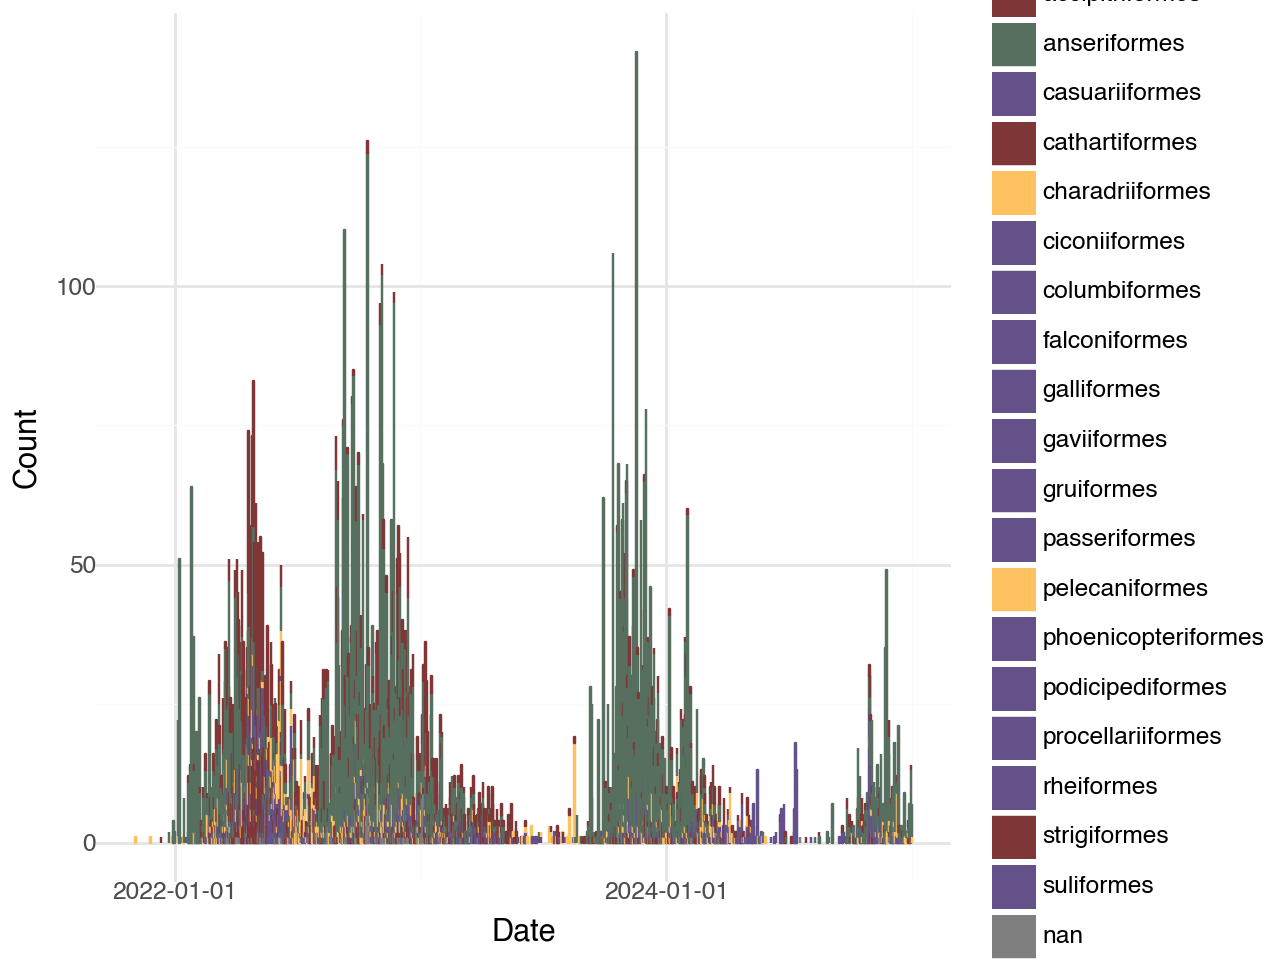

/Users/claramal/miniconda3/lib/python3.11/site-packages/plotnine/ggplot.py:606: PlotnineWarning: Saving 10 x 7 in image.
/Users/claramal/miniconda3/lib/python3.11/site-packages/plotnine/ggplot.py:607: PlotnineWarning: Filename: ./metadata/detections_data/detections_over_time_hostcolor.pdf


In [19]:
# Plot detections over time

host_colors = {"anseriformes":"#566F5E",
               "charadriiformes":"#FEC260", 
               "suliformes":"#65518A", 
               "pelecaniformes":"#FEC260", 
               "procellariiformes":"#65518A",
               "accipitriformes":"#7E3636", 
               "falconiformes":"#65518A", 
               "strigiformes":"#7E3636",
               "passeriformes":"#65518A", 
               "columbiformes":"#65518A", 
               "podicipediformes":"#65518A", 
               "galliformes":"#65518A", 
               "gaviiformes":"#65518A", 
               "gruiformes":"#65518A", 
               "phoenicopteriformes":"#65518A", 
               "ciconiiformes":"#65518A", 
               "cathartiformes":"#7E3636", 
               "rheiformes":"#65518A", 
               "casuariiformes":"#65518A"
              }

flyway_colors = {"AtlanticFlyway":"#AA7722", "MississippiFlyway":"#5E9B82", "CentralFlyway":"#C593D1", "PacificFlyway":"#2B57B3", "unknown":"#9C9C9C"}

all_detect_final["Collection Date"]= pd.to_datetime(all_detect_final["Collection Date"])

detections_over_time = (
    ggplot(all_detect_final, aes(x = "Collection Date", color = "Host_Order", fill = "Host_Order"))
    # ggplot(all_detect_final, aes(x = "Collection Date", color = "Flyway", fill = "Flyway"))
    + geom_bar(stat = "count")
    + scale_color_manual(host_colors)
    + scale_fill_manual(host_colors)
    # + scale_color_manual(flyway_colors)
    # + scale_fill_manual(flyway_colors)
    + labs(x = "Date", y = "Count")
    + theme_minimal()
)

detections_over_time.show()

# detections_over_time.save(filename = './metadata/detections_data/detections_over_time_hostcolor.pdf', height=7, width=10, units = 'in', dpi=750)

In [39]:
print(all_detect_final.columns)

Index(['Unnamed: 0', 'Collection Date', 'Location', 'Avian_Host', 'Country',
       'Flyway', 'Latitude_Group', 'Host_Order', 'Host_Broad',
       'Sample_Method'],
      dtype='object')


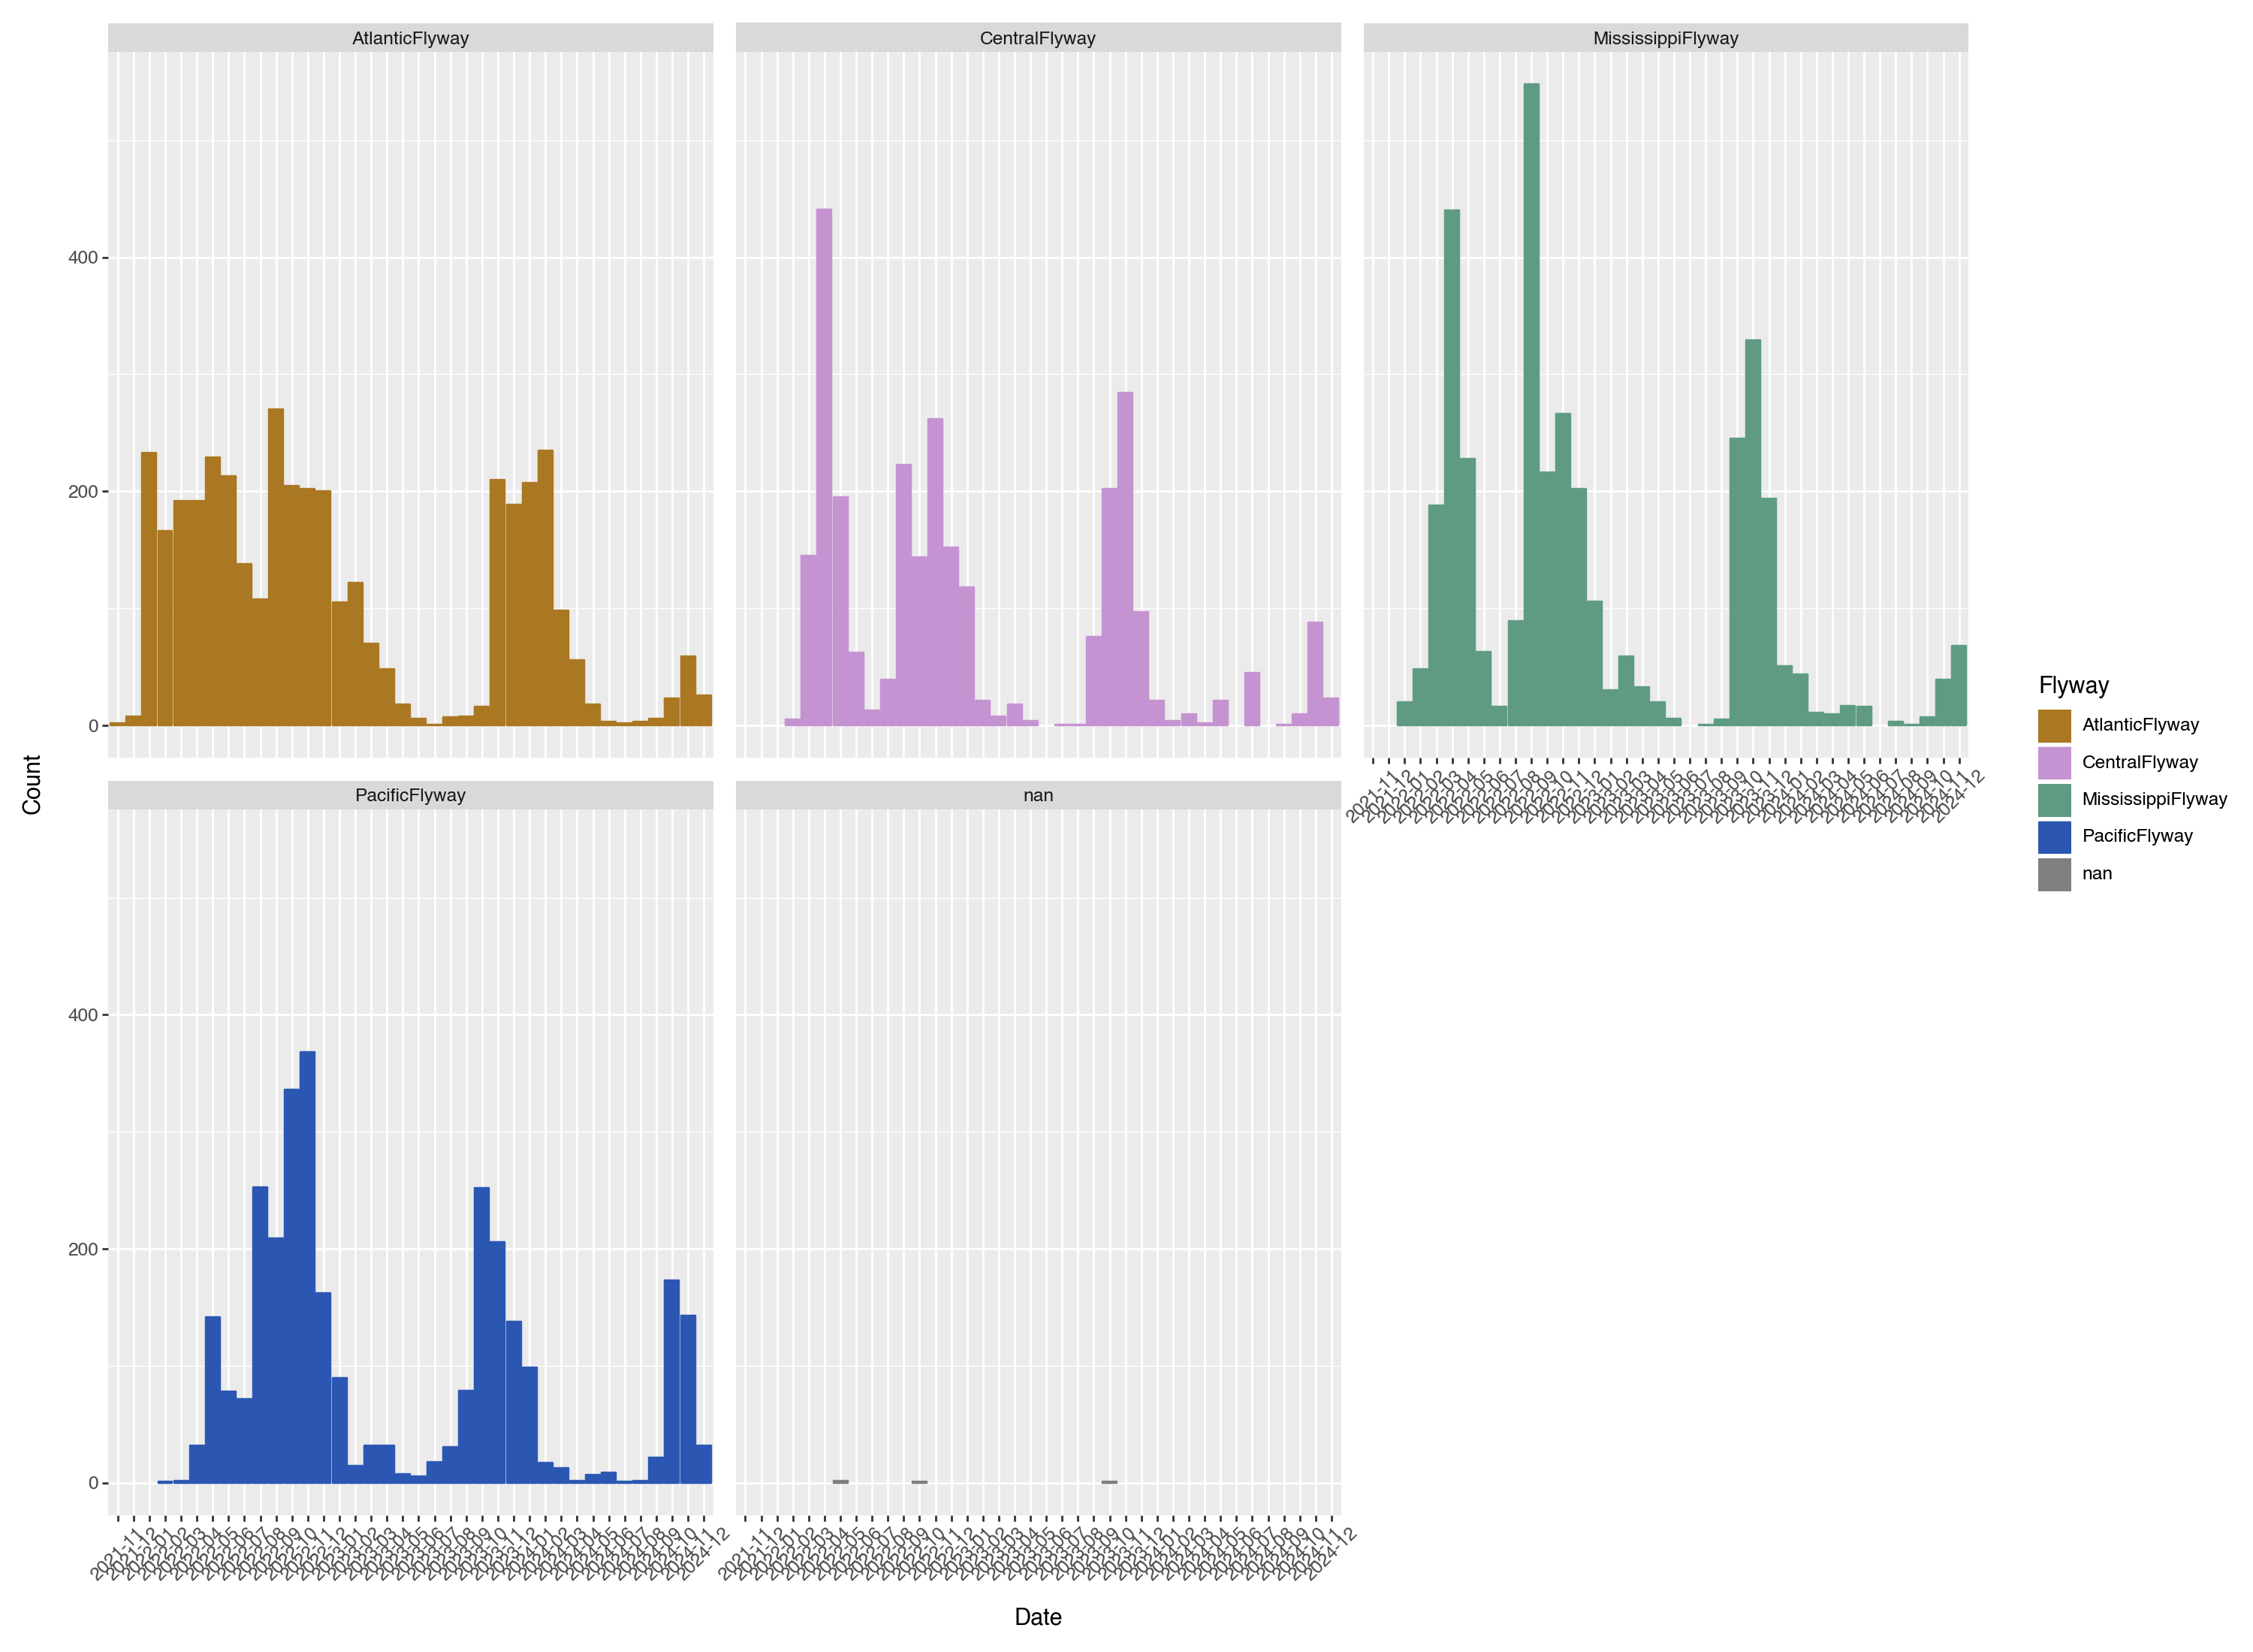

In [7]:
# Cases per flyway over time

all_detect_final["month_year"] = all_detect_final["Collection Date"].astype(str).str.split("-", expand = True)[0] + "-" + all_detect_final["Collection Date"].astype(str).str.split("-", expand = True)[1]

flyway_colors = {"AtlanticFlyway":"#AA7722", "MississippiFlyway":"#5E9B82", "CentralFlyway":"#C593D1", "PacificFlyway":"#2B57B3", "unknown":"#9C9C9C"}


flyway_over_time = (
    ggplot(all_detect_final, aes(x = "month_year", color = "Flyway", fill = "Flyway"))
    + geom_bar(stat = "count")
    + facet_wrap("Flyway")
    + scale_color_manual(flyway_colors)
    + scale_fill_manual(flyway_colors)
    + labs(x = "Date", y = "Count")
    + theme(axis_text_x=element_text(rotation=45))
    + theme(figure_size = (15,11))
)

flyway_over_time.show()

#flyway_over_time.save(filename = './metadata/detections_data/detections_by month_flyway.pdf', height=7, width=10, units = 'in', dpi=750)

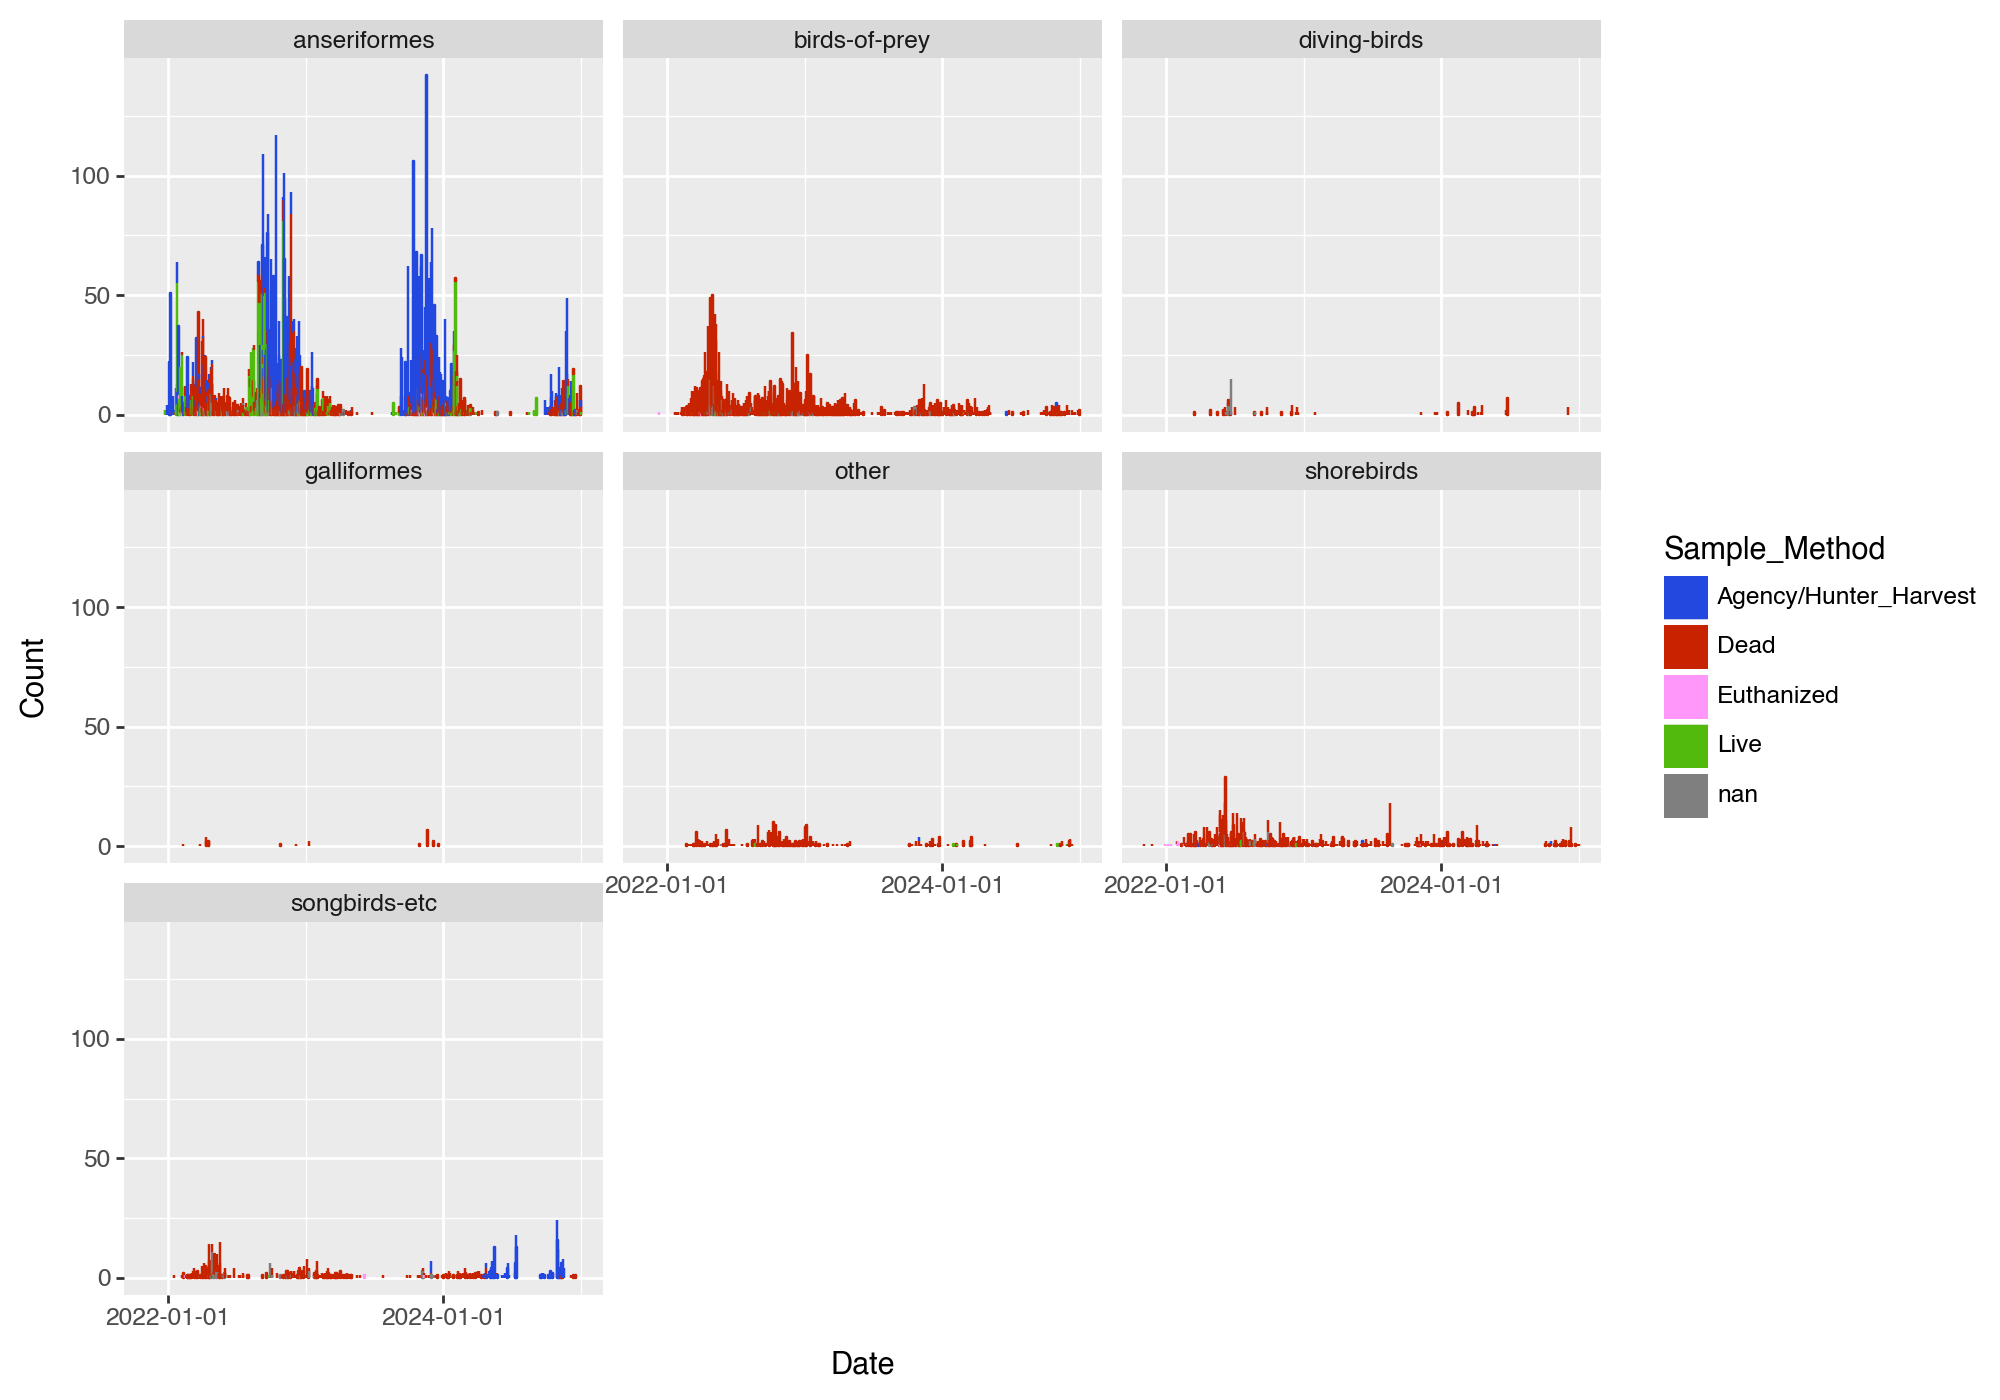

/Users/claramal/miniconda3/lib/python3.11/site-packages/plotnine/ggplot.py:606: PlotnineWarning: Saving 10 x 7 in image.
/Users/claramal/miniconda3/lib/python3.11/site-packages/plotnine/ggplot.py:607: PlotnineWarning: Filename: ./metadata/detections_data/sampling_method_over_time.pdf


In [8]:
# Plot: how are hosts sampled over time

all_detect_final["Collection Date"]= pd.to_datetime(all_detect_final["Collection Date"])

sample_method_colors = {"Dead":"#C72300",
                        "Live":"#52BA0D",
                        "Euthanized":"#FF96F9",
                        "Agency/Hunter_Harvest":"#2248E0"
                       }

host_sampled = (
    ggplot(all_detect_final, aes(x = "Collection Date", color = "Sample_Method", fill = "Sample_Method"))
    + geom_bar(stat = "count")
    + facet_wrap("Host_Broad")
    + scale_color_manual(sample_method_colors)
    + scale_fill_manual(sample_method_colors)
    + labs(x = "Date", y = "Count")
    + theme(figure_size = (10,7))
)

host_sampled.show()

host_sampled.save(filename = './metadata/detections_data/sampling_method_over_time.pdf', height=7, width=10, units = 'in', dpi=750)

In [76]:
# I have a combined shapefile for North America now

Nam_path = "./metadata/shapefiles/north_america/north_america.shp"
NAm_gdf = gpd.read_file(Nam_path)

NAm_gdf["geometry_name"] = NAm_gdf["name"].combine_first(NAm_gdf["PRNAME"])
columns = ["geometry", "geometry_name", "place", "type", "latitude", "longitude", "fips", "region", "gadm_level"]
NAm_gdf = NAm_gdf.loc[0:, columns]

NAm_gdf = NAm_gdf.to_crs("EPSG:4326")

In [79]:
# Create a DataFrame of lat/lon from the geometries

def geom_to_df(geom, region_name):
    if isinstance(geom, Polygon):
        coords = list(geom.exterior.coords)
        df = pd.DataFrame(coords, columns=['lon', 'lat'])
        df['region'] = region_name
        df['group'] = f"{region_name}_0"
        return df

    elif isinstance(geom, MultiPolygon):
        dfs = []
        for i, part in enumerate(geom.geoms):
            coords = list(part.exterior.coords)
            df = pd.DataFrame(coords, columns=['lon', 'lat'])
            df['region'] = region_name
            df['group'] = f"{region_name}_{i}"
            dfs.append(df)
            # Add NaN to separate parts (important for line-based plotting)
            dfs.append(pd.DataFrame({
                'lon': [np.nan],
                'lat': [np.nan],
                'region': [region_name],
                'group': [f"{region_name}_{i}"]
            }))
        return pd.concat(dfs, ignore_index=True)

    if isinstance(geom, LineString):
        coords = list(geom.coords)
        df = pd.DataFrame(coords, columns=['lon', 'lat'])
        df['region'] = region_name
        df['group'] = f"{region_name}_0"
        return df

    elif isinstance(geom, MultiLineString):
        dfs = []
        for i, part in enumerate(geom.geoms):
            coords = list(part.coords)
            df = pd.DataFrame(coords, columns=['lon', 'lat'])
            df['region'] = region_name
            df['group'] = f"{region_name}_{i}"
            dfs.append(df)
#            dfs.append(pd.DataFrame({'lon': [np.nan],'lat': [np.nan],'region': [region_name],'group': [f"{region_name}_{i}"]}))
        return pd.concat(dfs, ignore_index=True)

    else:
        return pd.DataFrame(columns=['lon', 'lat', 'region', 'group'])

In [80]:
# Apply to all rows

map_df = pd.concat([
    geom_to_df(row.geometry, row['geometry_name']) for idx, row in NAm_gdf.iterrows()], ignore_index=True)

In [81]:
p = (
    ggplot(map_df) +
    geom_path(aes(x='lon', y='lat', group='group'), color='gray') +
    coord_fixed() +
    theme_minimal() +
    theme(figure_size=(25, 17)) +
    labs(title='Map of North America', x = "Latitude", y = "Longitude")
)

p.show()

/Users/claramal/miniconda3/lib/python3.11/site-packages/plotnine/geoms/geom_path.py:100: PlotnineWarning: geom_path: Removed 1 rows containing missing values.
Exception ignored in: <bound method IPythonKernel._clean_thread_parent_frames of <ipykernel.ipkernel.IPythonKernel object at 0x10cfe2fd0>>
Traceback (most recent call last):
  File "/Users/claramal/miniconda3/lib/python3.11/site-packages/ipykernel/ipkernel.py", line 775, in _clean_thread_parent_frames
    def _clean_thread_parent_frames(

KeyboardInterrupt: 


KeyboardInterrupt: 

In [91]:
all_detect_final_countlocation = pd.DataFrame(all_detect_final["Location"].value_counts()).reset_index()

lat_coord_dict = {loc: data['latitude'] for loc, data in locations_dict.items()}
lon_coord_dict = {loc: data['longitude'] for loc, data in locations_dict.items()}

# Map to the detections
all_detect_final_countlocation["Flyway"] = all_detect_final_countlocation["Location"].map(flyways_dict)
all_detect_final_countlocation["Latitude_Group"] = all_detect_final_countlocation["Location"].map(latitude_dict)
all_detect_final_countlocation["Latitude"] = all_detect_final_countlocation["Location"].map(lat_coord_dict)
all_detect_final_countlocation["Longitude"] = all_detect_final_countlocation["Location"].map(lon_coord_dict)

In [100]:
seqs_per_location_map = (
    ggplot(map_df) +
    geom_path(aes(x='lon', y='lat', group='group'), color='gray') +
    geom_point(data=all_detect_final_countlocation, mapping=aes(x='Longitude', y='Latitude', size='count', fill = 'Flyway'), alpha=0.6) +
    scale_fill_manual(values = {"AtlanticFlyway":"#AA7722", "MississippiFlyway":"#5E9B82", "CentralFlyway":"#C593D1", "PacificFlyway":"#2B57B3", "unknown":"#9C9C9C", "nan":"#9C9C9C"},
                      name = "Flyway",
                      labels = {"AtlanticFlyway":"Atlantic", "MississippiFlyway":"Mississippi", "CentralFlyway":"Central", "PacificFlyway":"Pacific", "unknown":"Unknown", "nan":"Unknown"}) +
    scale_size_continuous(name="Count", range=(3, 15)) +
    # coord_fixed() +
    theme(text=element_text(size=24), legend_title=element_text(size=30), legend_text=element_text(size=24), legend_key_size=10) + 
    theme(figure_size=(15, 10)) +
    theme_minimal()
    # labs(title='Detection Counts by Location')
)

/Users/claramal/miniconda3/lib/python3.11/site-packages/plotnine/geoms/geom_path.py:100: PlotnineWarning: geom_path: Removed 1 rows containing missing values.
/Users/claramal/miniconda3/lib/python3.11/site-packages/plotnine/layer.py:364: PlotnineWarning: geom_point : Removed 3 rows containing missing values.


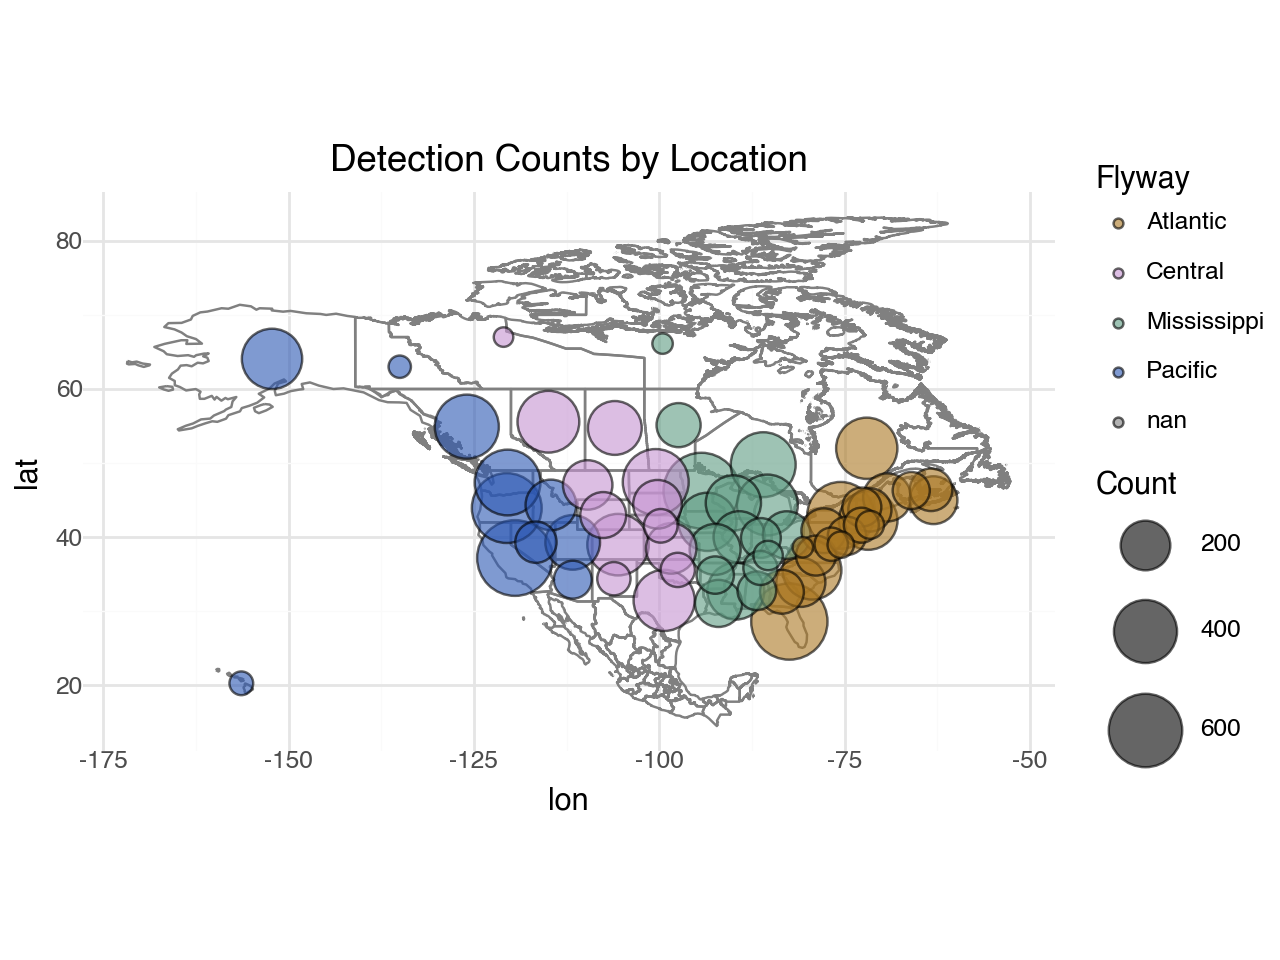

In [93]:
seqs_per_location_map.show()
#seqs_per_location_map.save(filename = './metadata/exploratory_data_analysis/HAseqs_per_location_map.png', height=10, width=20, units = 'in', dpi=750)
#seqs_per_location_map.save(filename = './metadata/exploratory_data_analysis/2022seqs_per_location_map.png', height=10, width=20, units = 'in', dpi=750)

In [101]:
seqs_per_location_map.save(filename = './metadata/detections_data/detections_per_location.pdf', height=10, width=20, units = 'in', dpi=750)

/Users/claramal/miniconda3/lib/python3.11/site-packages/plotnine/ggplot.py:606: PlotnineWarning: Saving 20 x 10 in image.
/Users/claramal/miniconda3/lib/python3.11/site-packages/plotnine/ggplot.py:607: PlotnineWarning: Filename: ./metadata/detections_data/detections_per_location.pdf
/Users/claramal/miniconda3/lib/python3.11/site-packages/plotnine/geoms/geom_path.py:100: PlotnineWarning: geom_path: Removed 1 rows containing missing values.
/Users/claramal/miniconda3/lib/python3.11/site-packages/plotnine/layer.py:364: PlotnineWarning: geom_point : Removed 3 rows containing missing values.
